# Liveability exploration

Explore amenity access for Greater Melbourne rental listings: load cleaned properties with amenity distances, map mean nearest-amenity distance by SA2, compare amenity access against distance to the CBD, and compare mean rent per bedroom against distance to the CBD.

## Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
from shapely.geometry import Point
import statsmodels.api as sm

ROOT = Path("../..")
DATA = ROOT / "data"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

# Nice km ticks for log-scaled distance axes / colourbars
KM_TICK_CANDIDATES = np.array(
    [0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50]
)


def km_ticks(vmin, vmax):
    return KM_TICK_CANDIDATES[(KM_TICK_CANDIDATES >= vmin) & (KM_TICK_CANDIDATES <= vmax)]

## Data

### Load properties + amenities

- `cleaned_properties.csv` — scraped rent.com.au listings after cleaning
- `listings_with_amenity_distances.csv` — nearest-amenity distances and counts (schools, parks, transit, supermarkets)

Joined on `latitude` / `longitude` (amenity features are unique per location).

In [2]:
listings = pd.read_csv(DATA / "preprocessed_data" / "cleaned_properties.csv")
listings["suburb"] = listings["suburb"].str.strip().str.lower()

amenities = pd.read_csv(DATA / "amenity_data" / "listings_with_amenity_distances.csv")

amenity_cols = [
    "nearest_school_km",
    "school_count_2km",
    "nearest_train_station_km",
    "nearest_park_km",
    "park_count_2km",
    "nearest_supermarket_km",
    "supermarket_count_4km",
    "nearest_tram_stop_km",
    "tram_stop_capped",
    "nearest_bus_stop_km",
    "bus_stop_capped",
]

# Amenity features are identical for a given lat/lon; drop duplicates so the merge stays 1:1
amenities = amenities.drop_duplicates(subset=["latitude", "longitude"])[
    ["latitude", "longitude"] + amenity_cols
]

df = listings.merge(amenities, on=["latitude", "longitude"], how="left")

print(f"listings: {len(listings):,} | amenities (unique locs): {len(amenities):,} | merged: {len(df):,}")
print(f"amenity match rate: {df[amenity_cols[0]].notna().mean():.1%}")
df.head()

listings: 9,232 | amenities (unique locs): 8,090 | merged: 9,232
amenity match rate: 100.0%


,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,transit_score,walk_score,airconditioning_air-conditioning,airconditioning_ducted,...,services_available_pay_tv,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,nearest_school_km,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,-37.814688,144.941083,"1007/20 Rakaia Way,",docklands,3008,730.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,100,92.0,0,0,...,0,0,0,0,0,0,0,0,0,0.2239,4,1.7541,0.3272,27,0.2927,47,0.2090,False,0.4570,False
1,-37.813699,144.953926,"4408/601 Little Lonsdale Street,",cbd,3000,670.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,100,99.0,0,0,...,0,0,0,0,0,0,1,0,0,0.2451,7,0.5049,0.1751,42,0.5418,50,0.1963,False,0.1793,False
2,-37.930804,145.112401,"29 Bond Street,",clayton south,3169,615.0,House,3,1,0.0,3,0,0,0.0,0,0,45,76.0,0,0,...,0,0,0,0,0,0,0,0,0,0.8481,4,1.5133,0.4956,32,0.8235,13,3.0000,True,0.2838,False
3,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,540.0,Apartment,1,1,0.0,1,0,0,0.0,0,0,80,98.0,0,0,...,0,0,0,0,0,0,0,0,0,0.6413,11,0.2585,0.4311,35,0.2379,24,0.0904,False,0.3271,False
4,-37.923180,145.128629,"33/2 Greenfield Drive,",clayton,3168,550.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,65,58.0,0,0,...,0,0,0,0,0,0,0,0,0,0.8972,3,1.1356,0.7598,17,1.0678,12,3.0000,True,0.7769,False


### Aggregate listings to SA2

Choose an amenity column, join listings into Greater Melbourne SA2s, and compute:

1. Mean nearest-amenity distance per SA2
2. Straight-line distance from each SA2 centroid to the CBD (Melbourne GPO)

In [3]:
# Switch amenity here — one of:
#   nearest_school_km, nearest_train_station_km, nearest_park_km,
#   nearest_supermarket_km, nearest_tram_stop_km, nearest_bus_stop_km
AMENITY = "nearest_school_km"

# Melbourne GPO (approx. CBD reference point)
CBD_LAT, CBD_LON = -37.8136, 144.9631

zones = gpd.read_file(DATA / "geospatial_data" / "Vic_Area_Zones" / "Vic_Area_Zones.shp")
zones = zones[zones["GCC_NAME21"] == "Greater Melbourne"].copy()

# Project to metres for true straight-line distances (GDA2020 / MGA zone 55)
zones_m = zones.to_crs(epsg=7855)
cbd = (
    gpd.GeoSeries([Point(CBD_LON, CBD_LAT)], crs="EPSG:4326")
    .to_crs(zones_m.crs)
    .iloc[0]
)
zones_m["dist_cbd_km"] = zones_m.geometry.centroid.distance(cbd) / 1000.0

clean = df.dropna(subset=["latitude", "longitude", AMENITY]).copy()
points = gpd.GeoDataFrame(
    clean,
    geometry=gpd.points_from_xy(clean["longitude"], clean["latitude"]),
    crs="EPSG:4326",
).to_crs(zones.crs)

joined = gpd.sjoin(points, zones[["SA2_NAME21", "geometry"]], how="inner", predicate="within")
avg_by_sa2 = (
    joined.groupby("SA2_NAME21")[AMENITY]
    .mean()
    .reset_index(name="avg_amenity_km")
)

sa2 = (
    zones_m[["SA2_NAME21", "geometry", "dist_cbd_km"]]
    .merge(avg_by_sa2, on="SA2_NAME21", how="left")
)

print(f"AMENITY = {AMENITY}")
print(f"SA2s with listings: {sa2['avg_amenity_km'].notna().sum():,} / {len(sa2):,}")
sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km"]].sort_values("dist_cbd_km").head()

AMENITY = nearest_school_km
SA2s with listings: 343 / 361


,SA2_NAME21,dist_cbd_km,avg_amenity_km
24,Melbourne CBD - East,0.492020,0.604344
26,Melbourne CBD - West,0.520396,0.594187
25,Melbourne CBD - North,0.526832,0.814523
31,West Melbourne - Residential,1.299765,0.637317
29,Southbank (West) - South Wharf,1.320555,1.043053


## Mean amenity distance by SA2

Choropleth of mean nearest-amenity distance across Greater Melbourne SA2s (log colour scale). Change `AMENITY` in the aggregation cell above and re-run from there.

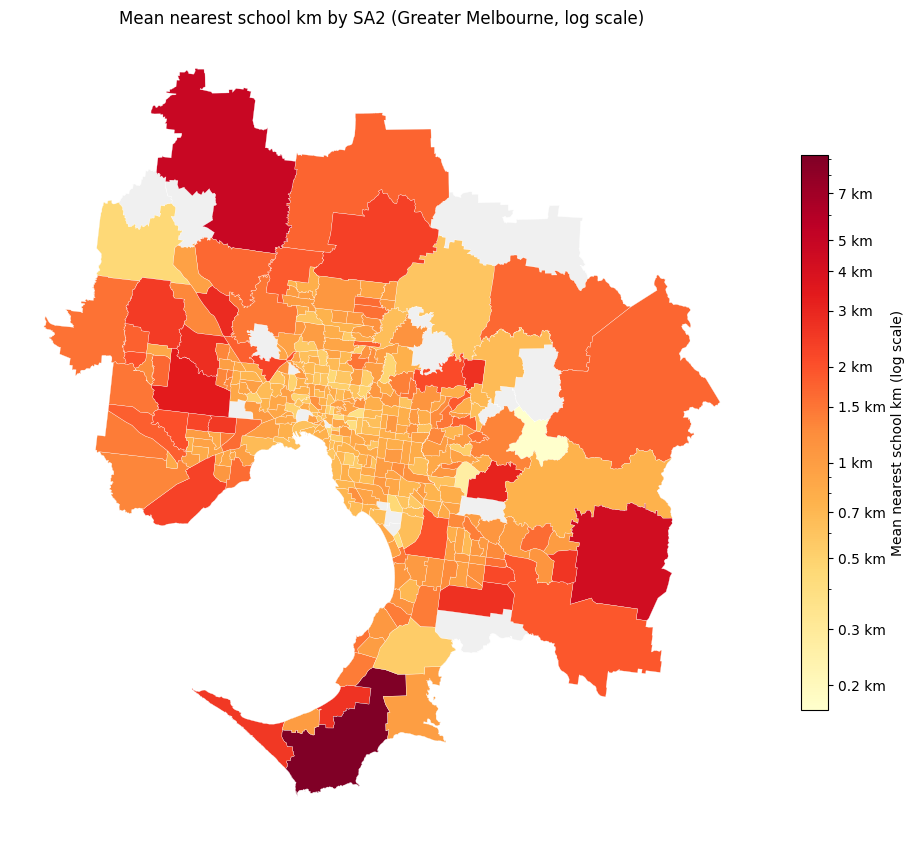

In [4]:
plot_data = sa2[sa2["avg_amenity_km"] > 0]
vmin, vmax = plot_data["avg_amenity_km"].min(), plot_data["avg_amenity_km"].max()
norm = LogNorm(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(12, 12))
sa2.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="avg_amenity_km",
    cmap="YlOrRd",
    norm=norm,
    legend=False,
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

sm = ScalarMappable(norm=norm, cmap="YlOrRd")
cbar = fig.colorbar(sm, ax=ax, shrink=0.6)
cbar.set_ticks(km_ticks(vmin, vmax))
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g} km"))
cbar.set_label(f"Mean {AMENITY.replace('_', ' ')} (log scale)")

ax.set_title(f"Mean {AMENITY.replace('_', ' ')} by SA2 (Greater Melbourne, log scale)")
ax.set_axis_off()
plt.show()

## Amenity access vs distance to CBD

Each point is one SA2: straight-line centroid→CBD distance vs mean nearest-amenity distance for listings in that SA2.

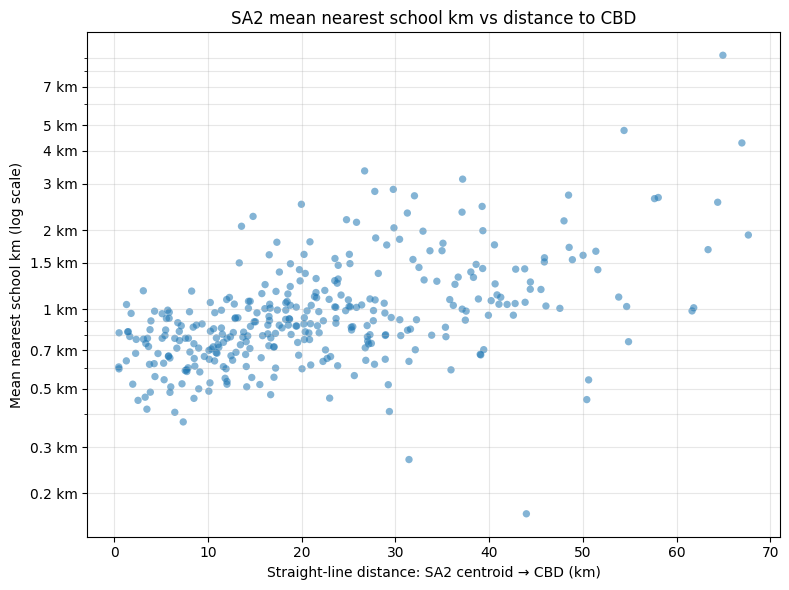

In [5]:
plot_sa2 = sa2[sa2["avg_amenity_km"] > 0]
plot_sa2[["dist_cbd_km", "avg_amenity_km"]].to_csv("transformed_data/amenity_access_vs_distance_to_cbd.csv")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    plot_sa2["dist_cbd_km"],
    plot_sa2["avg_amenity_km"],
    alpha=0.55,
    s=28,
    edgecolor="none",
)
ax.set_yscale("log")

vmin, vmax = plot_sa2["avg_amenity_km"].min(), plot_sa2["avg_amenity_km"].max()
ax.set_yticks(km_ticks(vmin, vmax))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g} km"))

ax.set_xlabel("Straight-line distance: SA2 centroid → CBD (km)")
ax.set_ylabel(f"Mean {AMENITY.replace('_', ' ')} (log scale)")
ax.set_title(f"SA2 mean {AMENITY.replace('_', ' ')} vs distance to CBD")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## Rent per bedroom vs distance to CBD

Each point is one SA2. Rent per bedroom is `weekly_rent_number / bedrooms` on listings with at least one bedroom; the SA2 value is the mean of those ratios. The predictor (x-axis) is the straight-line distance from the SA2 centroid to the CBD, shown on a log scale.

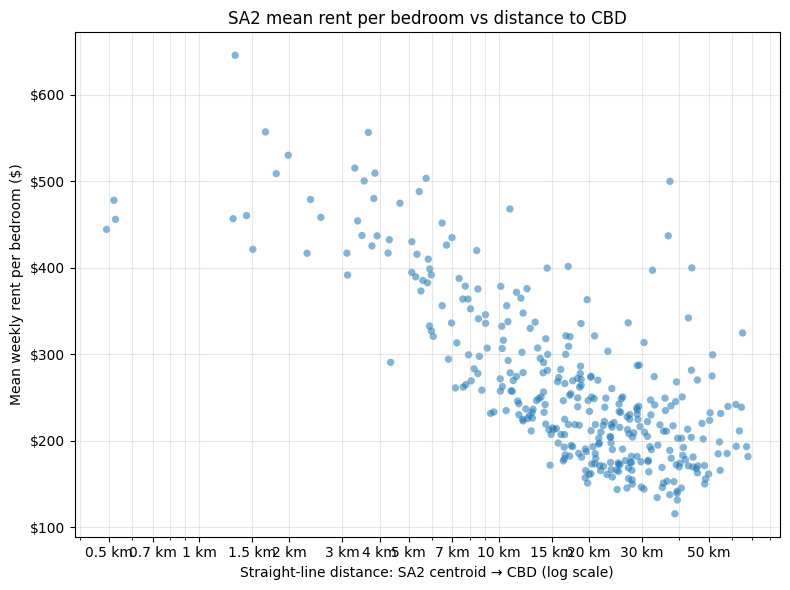

In [6]:
rentable = joined[
    joined["bedrooms"].gt(0) & joined["weekly_rent_number"].gt(0)
].copy()
rentable["rent_per_bedroom"] = rentable["weekly_rent_number"] / rentable["bedrooms"]

rent_by_sa2 = (
    rentable.groupby("SA2_NAME21")["rent_per_bedroom"]
    .mean()
    .reset_index(name="avg_rent_per_bedroom")
    .merge(sa2[["SA2_NAME21", "dist_cbd_km"]], on="SA2_NAME21", how="left")
)
rent_by_sa2 = rent_by_sa2[rent_by_sa2["dist_cbd_km"] > 0]

rent_by_sa2[["dist_cbd_km", "avg_rent_per_bedroom"]].to_csv("transformed_data/rent_per_bedroom_vs_distance_to_cbd.csv")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    rent_by_sa2["dist_cbd_km"],
    rent_by_sa2["avg_rent_per_bedroom"],
    alpha=0.55,
    s=28,
    edgecolor="none",
)
ax.set_xscale("log")
xmin, xmax = rent_by_sa2["dist_cbd_km"].min(), rent_by_sa2["dist_cbd_km"].max()
ax.set_xticks(km_ticks(xmin, xmax))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g} km"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:,.0f}"))

ax.set_xlabel("Straight-line distance: SA2 centroid → CBD (log scale)")
ax.set_ylabel("Mean weekly rent per bedroom ($)")
ax.set_title("SA2 mean rent per bedroom vs distance to CBD")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()